# Многомодальность распределения следующего товара

Проверяем гипотезу: распределение P(i | h) следующего товара при заданной истории в
текстовом пространстве товаров **многомодально**, то есть масса делится между несколькими
разнесёнными группами, а не лежит одним облаком. Если это так, генератор, который
выдаёт одну точку (регрессия в среднее), будет попадать между модами, и в этом смысл
генеративной (диффузионной / FM) постановки. Здесь проверяем гипотезу без диффузии,
двумя независимыми способами:

1. **Через SASRec как оценку P(i | h).** Берём softmax SASRec для тестовых пользователей,
   top-50 товаров с их вероятностями и кластеризуем их текстовые эмбеддинги. Считаем, у
   какой доли пользователей два и более *значимых* кластера (с заметной массой).
2. **Через сами данные.** Группируем пользователей с похожими историями (по среднему
   текстовому эмбеддингу последних товаров) и смотрим, насколько разбросаны их
   фактические следующие товары: одно облако или несколько.

**Как определяем кластер.** Иерархическая кластеризация (average linkage) по косинусному
расстоянию между текстовыми эмбеддингами (3072d, `3large_emb.pickle`). Дендрограмму режем на
расстоянии `D_CUT`: два кластера считаются разнесёнными, если среднее расстояние между их
товарами больше `D_CUT`. Масштаб `D_CUT` берём из данных: это `CUT_Q`-квантиль расстояния
между *случайными* парами товаров. Кластер **значимый**, если его масса (сумма вероятностей
внутри top-50 или доля товаров группы) не меньше `M_MIN`.

**Контроль.** Любое облако из 50 точек при достаточно малом пороге распадётся на куски, поэтому
каждую метрику сравниваем с двумя нулями, прогнанными той же процедурой:
* *унимодальный нуль*: вместо top-50 берём 50 товаров каталога, ближайших к взвешенному
  центру top-50, с тем же вектором вероятностей. Это одно компактное облако на реальных
  товарах, и оно показывает долю ложных срабатываний процедуры;
* *случайный нуль*: 50 случайных товаров с тем же вектором вероятностей. Это верхняя
  граница разброса.

Порогов два (`CUT_Q`, `M_MIN`), поэтому для обоих вопросов есть сетка чувствительности.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)                          # пути в yaml относительны корня проекта
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA

from builders import load_model_config
from data import build_dataloaders, load_item_embeddings

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
print(f'Корень проекта: {ROOT}')

Корень проекта: d:\Skoltech\Thesis\DiffText4Rec


In [2]:
# ════════════════════════════════════════════════════════════
# КОНФИГ
# ════════════════════════════════════════════════════════════
CONFIG_PATH = 'configs/sasrec.yaml'
CKPT_DIR    = 'checkpoints/sasrec'
EMB_PATH    = 'data/ATG/3large_emb.pickle'

TOP_N  = 50                        # товаров из P(i|h) на пользователя
CUT_Q  = 0.25                      # D_CUT = CUT_Q-квантиль косинусного расстояния случайных пар
M_MIN  = 0.10                      # значимый кластер: доля массы top-N / доля товаров группы
Q_GRID = (0.05, 0.10, 0.25, 0.50)  # сетка чувствительности по CUT_Q
M_GRID = (0.05, 0.10, 0.20)        # и по M_MIN

K_LAST    = 3      # представление истории: среднее эмбеддингов последних K_LAST товаров
GROUP     = 20     # размер группы похожих историй: якорь + GROUP-1 ближайших соседей
N_NEIGH   = 50     # соседей на пользователя для парного анализа
N_ANCHORS = 3000   # якорей для групп
SEED      = 42

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
rng = np.random.default_rng(SEED)
print(f'Device: {device}')

Device: cuda


## 0. Текстовое пространство и масштаб расстояний

Эмбеддинги нормированы, поэтому косинусное расстояние = 1 − cos. Абсолютные значения мало
что говорят из-за анизотропии (случайные пары далеко не ортогональны), так что порог
выражаем через квантиль расстояний случайных пар. Для ориентира рядом показано расстояние
между последним товаром истории и следующим товаром: это типичный «шаг» пользователя.

                         q01    q05    q10    q25    q50    q75
случайные пары         0.510  0.602  0.639  0.691  0.740  0.784
последний → следующий  0.452  0.587  0.630  0.686  0.738  0.782

D_CUT = q25 случайных пар = 0.691; шаг пользователя короче D_CUT в 27% переходов


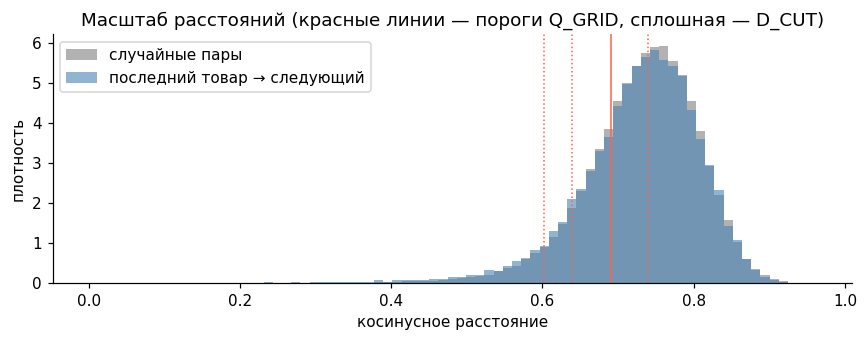

In [3]:
spec, cfg = load_model_config(CONFIG_PATH)
E = load_item_embeddings(EMB_PATH)
E /= np.linalg.norm(E, axis=1, keepdims=True)
N_ITEMS, PAD = E.shape[0], cfg.data.padding_idx
E_pad = np.vstack([E, np.zeros((1, E.shape[1]), np.float32)])   # строка PAD — нули

splits = {s: pd.read_pickle(Path(cfg.data.data_dir) / f'{s}_data.df') for s in ('train', 'val', 'test')}
all_df = pd.concat([d.assign(split=s) for s, d in splits.items()], ignore_index=True)

i, j = rng.integers(0, N_ITEMS, (2, 100_000)); keep = i != j
d_rand  = 1 - (E[i[keep]] * E[j[keep]]).sum(1)
last    = np.array([s[-1] for s in all_df['seq']])          # padding слева → последняя позиция реальна
d_trans = 1 - (E[last] * E[all_df['next'].to_numpy()]).sum(1)

def cut_at(q: float) -> float:
    return float(np.quantile(d_rand, q))

D_CUT = cut_at(CUT_Q)
qs = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75]
print(pd.DataFrame({'случайные пары': np.quantile(d_rand, qs),
                    'последний → следующий': np.quantile(d_trans, qs)},
                   index=[f'q{int(q * 100):02d}' for q in qs]).round(3).T)
print(f'\nD_CUT = q{int(CUT_Q * 100)} случайных пар = {D_CUT:.3f}; '
      f'шаг пользователя короче D_CUT в {np.mean(d_trans < D_CUT):.0%} переходов')

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(0, max(d_rand.max(), d_trans.max()), 80)
ax.hist(d_rand, bins, density=True, alpha=0.6, color='grey', label='случайные пары')
ax.hist(d_trans, bins, density=True, alpha=0.6, color='steelblue', label='последний товар → следующий')
for q in Q_GRID:
    ax.axvline(cut_at(q), color='tomato', lw=1, ls='-' if q == CUT_Q else ':')
ax.set_xlabel('косинусное расстояние'); ax.set_ylabel('плотность')
ax.set_title('Масштаб расстояний (красные линии — пороги Q_GRID, сплошная — D_CUT)'); ax.legend()
fig.tight_layout(); plt.show()

In [4]:
# ════════════════════════════════════════════════════════════
# Кластеризация, общая для обоих вопросов
# ════════════════════════════════════════════════════════════
def cos_linkage(X: np.ndarray) -> np.ndarray:
    # max(·, 0): у дубликатов float32 даёт расстояние −1e-7
    return linkage(np.maximum(pdist(X, 'cosine'), 0), method='average')


def cluster_masses(Z: np.ndarray, w: np.ndarray, d_cut: float):
    # Метки кластеров после разреза на d_cut и их массы (доли w), по убыванию массы
    lab  = fcluster(Z, t=d_cut, criterion='distance')
    mass = np.bincount(lab, weights=w)[1:] / w.sum()
    order = np.argsort(-mass)
    rank = np.empty_like(order); rank[order] = np.arange(len(order))
    return rank[lab - 1], mass[order]          # rank: 0 — самый тяжёлый кластер


def n_significant(Z, w, d_cut, m_min) -> int:
    return int((cluster_masses(Z, w, d_cut)[1] >= m_min).sum())


def second_mass(Z, w, d_cut) -> float:
    m = cluster_masses(Z, w, d_cut)[1]
    return float(m[1]) if len(m) > 1 else 0.0


def sig_table(Zs: dict, W: dict, d_cut: float, m_min: float) -> pd.DataFrame:
    # Распределение числа значимых кластеров: 0 — масса размазана по мелким кластерам
    rows = {}
    for name, Z_list in Zs.items():
        n = np.array([n_significant(Z, w, d_cut, m_min) for Z, w in zip(Z_list, W[name])])
        rows[name] = {'0 (размыто)': np.mean(n == 0), '1': np.mean(n == 1),
                      '2': np.mean(n == 2), '3+': np.mean(n >= 3), '≥2': np.mean(n >= 2)}
    return pd.DataFrame(rows).T


def sensitivity(Zs: dict, W: dict) -> dict:
    # Доля пользователей/групп с ≥2 значимыми кластерами на сетке Q_GRID × M_GRID
    out = {}
    for name, Z_list in Zs.items():
        g = np.zeros((len(M_GRID), len(Q_GRID)))
        for a, m in enumerate(M_GRID):
            for b, q in enumerate(Q_GRID):
                d = cut_at(q)
                g[a, b] = np.mean([n_significant(Z, w, d, m) >= 2 for Z, w in zip(Z_list, W[name])])
        out[name] = g
    return out


def plot_sensitivity(grids: dict, title: str):
    fig, axes = plt.subplots(1, len(grids), figsize=(4.3 * len(grids), 3.2))
    for ax, (name, g) in zip(axes, grids.items()):
        im = ax.imshow(g, vmin=0, vmax=1, cmap='viridis', aspect='auto')
        for a in range(g.shape[0]):
            for b in range(g.shape[1]):
                ax.text(b, a, f'{g[a, b]:.2f}', ha='center', va='center',
                        color='white' if g[a, b] < 0.6 else 'black', fontsize=9)
        ax.set_xticks(range(len(Q_GRID)), [f'q{int(q * 100)}\n{cut_at(q):.2f}' for q in Q_GRID])
        ax.set_yticks(range(len(M_GRID)), [f'{m:.2f}' for m in M_GRID])
        ax.set_xlabel('порог разреза D_CUT'); ax.set_ylabel('M_MIN'); ax.set_title(name)
    fig.colorbar(im, ax=axes, shrink=0.8, label='доля с ≥2 значимыми кластерами')
    fig.suptitle(title); plt.show()

## 1. Вопрос 1: P(i | h) по SASRec

### 1.1 Модель и калибровка температуры

SASRec обучен InfoNCE на косинусных логитах `cos(h, e_i) / τ`, τ = 0.07. Негативы
равномерные, поэтому поправка logQ постоянна и полный softmax по каталогу с тем же τ
согласован с обучением. Но sampled softmax на 64 негативах не обязан давать откалиброванную
*остроту* распределения, а от неё прямо зависит, сколько массы окажется во второстепенных
кластерах. Поэтому τ подбираем по NLL таргетов на val (одномерный поиск) и дальше работаем с
откалиброванным P(i | h) = softmax(cos / τ*). Результаты при τ = 0.07 даны для сравнения
в сводке.

checkpoints\sasrec\best.pt | эпоха 50 | метрики val: {'HR@10': 0.04636785015463829, 'NDCG@10': 0.03260510787367821, 'HR@20': 0.06439979374408722, 'NDCG@20': 0.03708765283226967}


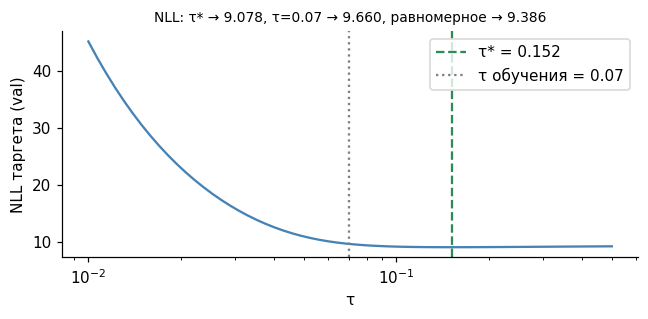

In [5]:
model = spec.build(cfg).to(device).eval()
ckpt_path = Path(CKPT_DIR) / 'best.pt'
ckpt = torch.load(ckpt_path, map_location='cpu', mmap=True)
model.load_state_dict(ckpt['model_state'])
print(f'{ckpt_path} | эпоха {ckpt["epoch"]} | метрики val: {ckpt["metrics"]}')

loaders = build_dataloaders(data_dir=cfg.data.data_dir, batch_size=512, num_workers=0,
                            seq_len=cfg.data.max_seq_len, splits=('val', 'test'))


@torch.no_grad()
def cosine_scores(loader):
    W = F.normalize(model._item_table(), dim=-1)
    cos, tgt, hist = [], [], []
    for b in loader:
        h = model(b['history'].to(device), b['mask'].to(device))
        cos.append((F.normalize(h, dim=-1) @ W.T).cpu())
        tgt.append(b['target']); hist.append(b['history'])
    return torch.cat(cos), torch.cat(tgt), torch.cat(hist)


cos_val,  y_val,  _         = cosine_scores(loaders['val'])
cos_test, y_test, hist_test = cosine_scores(loaders['test'])


def nll(cos, y, tau):
    return (torch.logsumexp(cos / tau, 1) - cos[torch.arange(len(y)), y] / tau).mean().item()


taus = np.geomspace(0.01, 0.5, 60)
nll_val = np.array([nll(cos_val, y_val, t) for t in taus])
TAU_TRAIN, TAU = model.temperature, float(taus[nll_val.argmin()])

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(taus, nll_val, color='steelblue')
ax.axvline(TAU, color='seagreen', ls='--', label=f'τ* = {TAU:.3f}')
ax.axvline(TAU_TRAIN, color='grey', ls=':', label=f'τ обучения = {TAU_TRAIN}')
ax.set_xscale('log'); ax.set_xlabel('τ'); ax.set_ylabel('NLL таргета (val)'); ax.legend()
ax.set_title(f'NLL: τ* → {nll_val.min():.3f}, τ=0.07 → {nll(cos_val, y_val, TAU_TRAIN):.3f}, '
             f'равномерное → {np.log(N_ITEMS):.3f}', fontsize=9)
fig.tight_layout(); plt.show()

### 1.2 Сколько распределения попадает в top-50

Top-50 рассматриваем как носитель P(i | h), внутри него перенормируем. Если top-50 покрывает
малую долю массы, выводы относятся к голове распределения, а не ко всему распределению.
Эффективное число товаров exp(H) показывает, насколько распределение размазано по каталогу.

test: 1942 пользователей | таргет в top-50: 0.092
                     mean       10%       50%       90%
масса top-50        0.041     0.031     0.038     0.053
exp(H), товаров  8797.871  8082.763  8889.860  9410.627


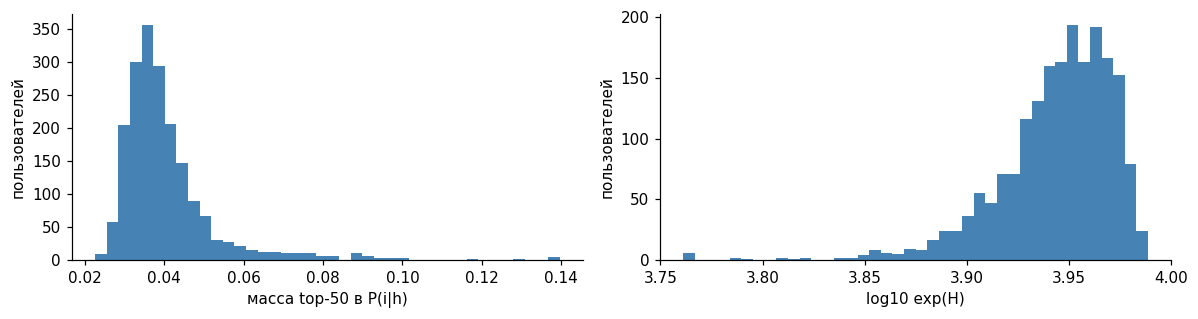

In [6]:
def top_support(cos, tau):
    P = torch.softmax(cos / tau, dim=1)
    H = -(P * torch.log(P.clamp_min(1e-30))).sum(1)
    p, idx = P.topk(TOP_N, dim=1)
    return p.numpy(), idx.numpy(), p.sum(1).numpy(), H.exp().numpy()


top_p, top_i, coverage, eff_n = top_support(cos_test, TAU)
y = y_test.numpy()
hit = (top_i == y[:, None]).any(1)
print(f'test: {len(y)} пользователей | таргет в top-{TOP_N}: {hit.mean():.3f}')
print(pd.DataFrame({'масса top-50': coverage, 'exp(H), товаров': eff_n})
        .describe(percentiles=[0.1, 0.5, 0.9]).T[['mean', '10%', '50%', '90%']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(coverage, 40, color='steelblue'); axes[0].set_xlabel(f'масса top-{TOP_N} в P(i|h)')
axes[1].hist(np.log10(eff_n), 40, color='steelblue'); axes[1].set_xlabel('log10 exp(H)')
for ax in axes: ax.set_ylabel('пользователей')
fig.tight_layout(); plt.show()

### 1.3 Кластеры в top-50 против нулей

Для каждого пользователя строим три набора из 50 товаров с одинаковым вектором весов
(перенормированные вероятности top-50):
* **SASRec**: сам top-50;
* **унимодальный нуль**: 50 товаров, ближайших к взвешенному центру top-50 (самый близкий
  получает самую большую вероятность);
* **случайный нуль**: 50 случайных товаров.

In [7]:
def build_sets(top_p, top_i):
    w = top_p / top_p.sum(1, keepdims=True)
    centre = (w[:, :, None] * E[top_i]).sum(1)
    centre /= np.linalg.norm(centre, axis=1, keepdims=True)
    uni_i  = np.argsort(-(centre @ E.T), axis=1)[:, :TOP_N]
    rand_i = np.argsort(rng.random((len(w), N_ITEMS)), axis=1)[:, :TOP_N]
    sets = {'SASRec': top_i, 'унимодальный нуль': uni_i, 'случайный нуль': rand_i}
    Zs = {name: [cos_linkage(E[s]) for s in S] for name, S in sets.items()}
    return sets, Zs, {name: list(w) for name in sets}


sets1, Z1, W1 = build_sets(top_p, top_i)
tab1 = sig_table(Z1, W1, D_CUT, M_MIN)
print(f'Число значимых кластеров, D_CUT = {D_CUT:.3f} (q{int(CUT_Q * 100)}), M_MIN = {M_MIN}')
tab1.round(3)

Число значимых кластеров, D_CUT = 0.691 (q25), M_MIN = 0.1


,0 (размыто),1,2,3+,≥2
SASRec,0.0,0.012,0.126,0.863,0.988
унимодальный нуль,0.0,0.999,0.001,0.000,0.001
случайный нуль,0.0,0.019,0.174,0.807,0.981


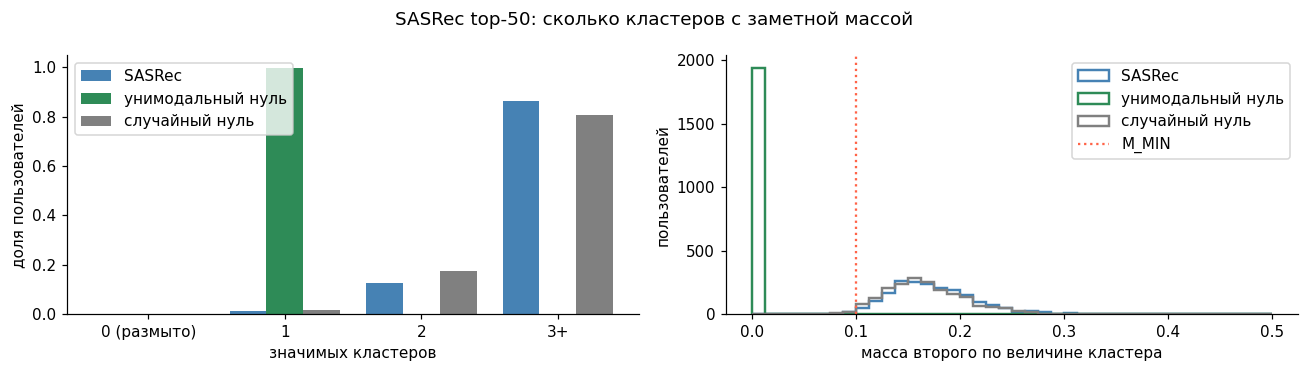

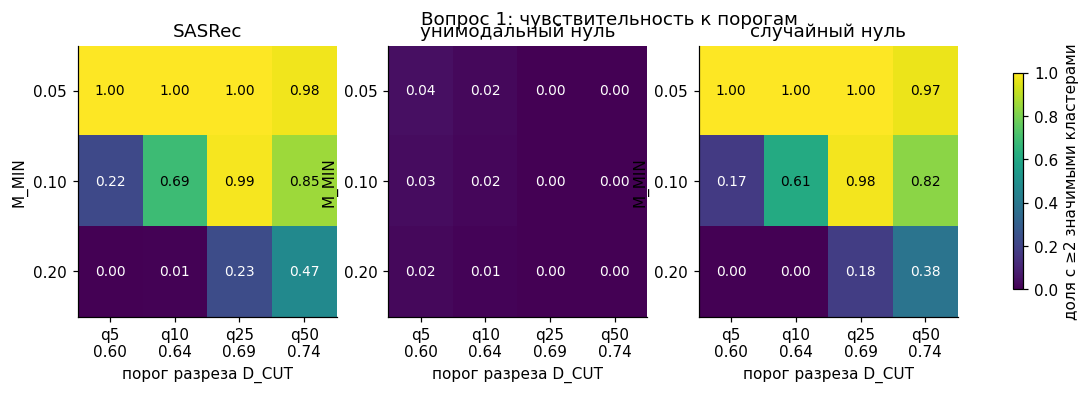

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
colors = {'SASRec': 'steelblue', 'унимодальный нуль': 'seagreen', 'случайный нуль': 'grey'}

ax = axes[0]
x = np.arange(4); width = 0.27
for k, (name, row) in enumerate(tab1.iterrows()):
    ax.bar(x + (k - 1) * width, row[['0 (размыто)', '1', '2', '3+']], width, color=colors[name], label=name)
ax.set_xticks(x, ['0 (размыто)', '1', '2', '3+']); ax.set_xlabel('значимых кластеров')
ax.set_ylabel('доля пользователей'); ax.legend()

ax = axes[1]
for name in Z1:
    m2 = [second_mass(Z, w, D_CUT) for Z, w in zip(Z1[name], W1[name])]
    ax.hist(m2, bins=np.linspace(0, 0.5, 41), histtype='step', lw=1.6, color=colors[name], label=name)
ax.axvline(M_MIN, color='tomato', ls=':', label='M_MIN')
ax.set_xlabel('масса второго по величине кластера'); ax.set_ylabel('пользователей'); ax.legend()
fig.suptitle('SASRec top-50: сколько кластеров с заметной массой'); fig.tight_layout(); plt.show()

plot_sensitivity(sensitivity(Z1, W1), 'Вопрос 1: чувствительность к порогам')

### 1.4 Реальны ли второстепенные моды

Если P(i | h) откалиброван и второстепенные кластеры не артефакт, фактический таргет должен
попадать в них примерно с той частотой, какую предсказывает их масса. Для пользователей,
у которых таргет попал в top-50, смотрим, в каком кластере он лежит, и сравниваем с
ожидаемой частотой: средней массой соответствующей категории кластеров, взвешенной
покрытием top-50 (P(таргет в top-50) ≈ покрытие).

In [9]:
cats = ['главный кластер', 'другой значимый', 'незначимые']
obs, exp_ = np.zeros(3), np.zeros(3)
for u, (Z, w) in enumerate(zip(Z1['SASRec'], W1['SASRec'])):
    rank, mass = cluster_masses(Z, w, D_CUT)
    cat_of_rank = np.where(np.arange(len(mass)) == 0, 0, np.where(mass >= M_MIN, 1, 2))
    exp_ += coverage[u] * np.bincount(cat_of_rank, weights=mass, minlength=3)
    if hit[u]:
        pos = np.flatnonzero(top_i[u] == y[u])[0]
        obs[cat_of_rank[rank[pos]]] += 1

calib = pd.DataFrame({'ожидаемая доля (масса)': exp_ / exp_.sum(),
                      'фактическая доля таргетов': obs / obs.sum()}, index=cats)
print(f'пользователей с таргетом в top-{TOP_N}: {int(obs.sum())}')
calib.round(3)

пользователей с таргетом в top-50: 179


,ожидаемая доля (масса),фактическая доля таргетов
главный кластер,0.268,0.313
другой значимый,0.369,0.358
незначимые,0.363,0.330


### 1.5 Примеры

Пользователи с самым тяжёлым вторым кластером. PCA на объединении top-50, истории и таргета.
Размер точки ∝ вероятности, цвет = кластер (серый = незначимый), × = товары истории,
★ = фактический следующий товар. Названий товаров в проекте нет (нет маппинга индекс → ASIN),
так что показана только геометрия.

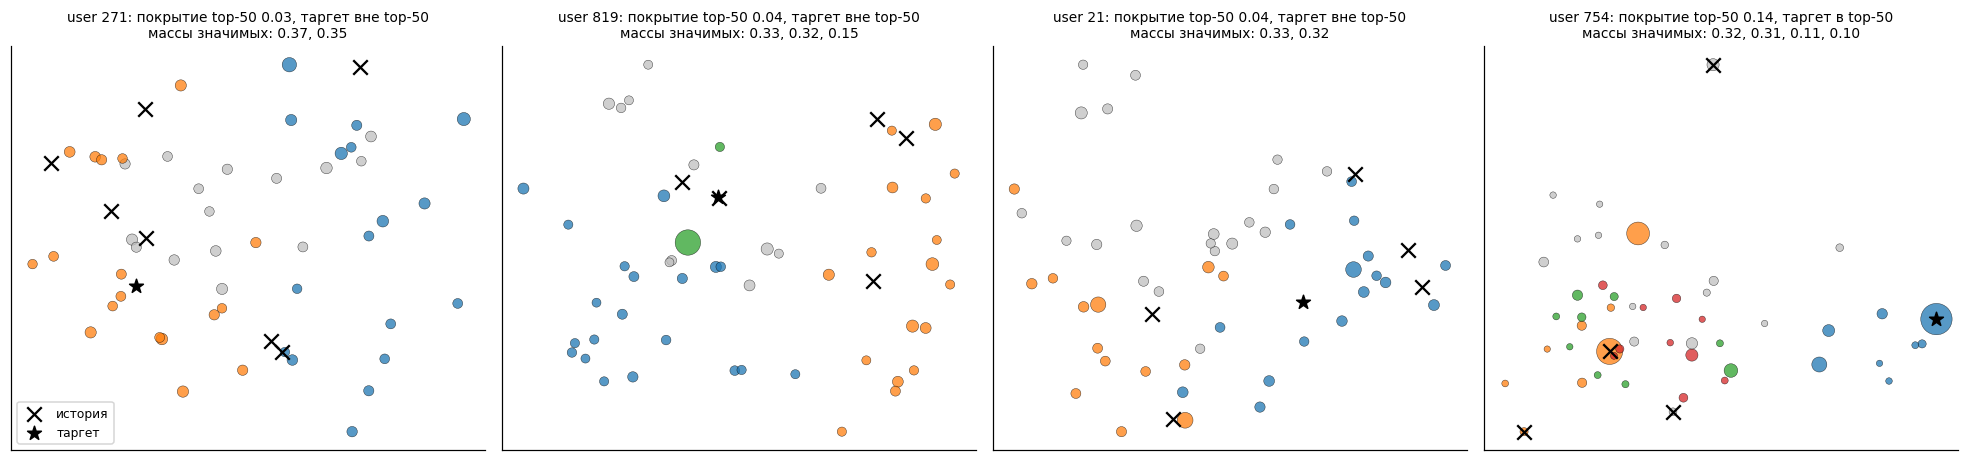

In [10]:
def plot_modes(ax, items, w, Z, extra=(), title=''):
    # extra: [(индексы, маркер, подпись)] — точки, которые участвуют в PCA, но не в кластеризации
    rank, mass = cluster_masses(Z, w, D_CUT)
    pts = [E[items]] + [E[np.atleast_1d(e)] for e, _, _ in extra]
    xy = PCA(2, random_state=SEED).fit_transform(np.vstack(pts))
    cmap = plt.get_cmap('tab10')
    col = [cmap(r) if mass[r] >= M_MIN else (0.75, 0.75, 0.75, 1) for r in rank]
    ax.scatter(xy[:len(items), 0], xy[:len(items), 1], s=2000 * w / w.sum() + 8, c=col,
               alpha=0.75, edgecolors='k', linewidths=0.3)
    off = len(items)
    for e, marker, label in extra:
        n = len(np.atleast_1d(e))
        ax.scatter(xy[off:off + n, 0], xy[off:off + n, 1], marker=marker, s=90, c='k', label=label)
        off += n
    sig = mass[mass >= M_MIN]
    ax.set_title(title + f'\nмассы значимых: {", ".join(f"{m:.2f}" for m in sig)}', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])


m2 = np.array([second_mass(Z, w, D_CUT) for Z, w in zip(Z1['SASRec'], W1['SASRec'])])
show = np.argsort(-m2)[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, u in zip(axes, show):
    h = hist_test[u].numpy(); h = h[h != PAD]
    plot_modes(ax, top_i[u], W1['SASRec'][u], Z1['SASRec'][u],
               extra=[(h, 'x', 'история'), (y[u], '*', 'таргет')],
               title=f'user {u}: покрытие top-50 {coverage[u]:.2f}, таргет {"в" if hit[u] else "вне"} top-50')
axes[0].legend(loc='lower left', fontsize=8)
fig.tight_layout(); plt.show()

In [17]:
# 1. Гипотеза сдвига: медианный cos «последний → следующий» при смещении индексов
nxt_all = all_df['next'].to_numpy()
for s in (-2, -1, 0, 1, 2):
    a, b = np.clip(last + s, 0, N_ITEMS - 1), np.clip(nxt_all + s, 0, N_ITEMS - 1)
    print(s, round(float(np.median((E[a] * E[b]).sum(1))), 3))

# 2. Training-free текстовый рекомендатель: скор = cos(среднее истории, товар)
h = hist_test.numpy(); m = (h != PAD)[..., None]
Hq = (E_pad[h] * m).sum(1); Hq /= np.linalg.norm(Hq, axis=1, keepdims=True)
top10 = np.argpartition(-(Hq @ E.T), 10, axis=1)[:, :10]
print('HR@10 text-only:', (top10 == y[:, None]).any(1).mean(), '| случайно:', 10 / N_ITEMS)

-2 0.263
-1 0.262
0 0.262
1 0.262
2 0.262
HR@10 text-only: 0.0010298661174047373 | случайно: 0.0008386447500838644


## 2. Вопрос 2: разброс следующих товаров у похожих историй

Здесь модели нет, только данные: объединяем train/val/test (все пары история → следующий
товар, точные дубликаты убираем). Представление истории: нормированное среднее текстовых
эмбеддингов последних `K_LAST` товаров. Похожие истории = ближайшие соседи по косинусу.

Оговорка: у соседей истории похожи, но не совпадают, поэтому разброс их следующих товаров
складывается из собственной многомодальности P(i | h) и из различий контекстов. Чтобы их
развести, смотрим на зависимость от близости историй: если при почти одинаковых историях
следующие товары всё равно разлетаются по разным далёким группам, это многомодальность,
а не шум контекста.

### 2.1 Парный анализ: близость историй против близости следующих товаров

In [11]:
key = all_df['seq'].map(tuple).astype(str) + '|' + all_df['next'].astype(str)
data = all_df.loc[~key.duplicated()].reset_index(drop=True)
print(f'пар история → следующий: {len(all_df)}, после удаления точных дубликатов: {len(data)}')

seqs = np.stack(data['seq'].to_numpy())[:, -K_LAST:]
Hr = E_pad[seqs].sum(1) / np.maximum((seqs != PAD).sum(1, keepdims=True), 1)
Hr = (Hr / np.linalg.norm(Hr, axis=1, keepdims=True)).astype(np.float32)
nxt = data['next'].to_numpy()
N = len(data)

# kNN по историям, на GPU чанками
Ht = torch.from_numpy(Hr).to(device)
nn_sim, nn_idx = [], []
for s in range(0, N, 2048):
    S = Ht[s:s + 2048] @ Ht.T
    S[torch.arange(S.shape[0]), torch.arange(s, s + S.shape[0])] = -2   # сам себе не сосед
    v, ix = S.topk(max(N_NEIGH, GROUP), dim=1)
    nn_sim.append(v.cpu().numpy()); nn_idx.append(ix.cpu().numpy())
nn_sim, nn_idx = np.vstack(nn_sim), np.vstack(nn_idx)
del Ht

# Пары: соседи (плотно покрывают высокую близость) + случайные (фон)
a_nn = np.repeat(np.arange(N), N_NEIGH); b_nn = nn_idx[:, :N_NEIGH].ravel()
a_r, b_r = rng.integers(0, N, (2, 200_000)); keep = a_r != b_r
A = np.concatenate([a_nn, a_r[keep]]); B = np.concatenate([b_nn, b_r[keep]])


def row_dot(X, a, b, chunk=50_000):
    # Скалярные произведения X[a[k]]·X[b[k]] чанками: пар ~1M, целиком (1M × 3072) не влезет
    return np.concatenate([(X[a[s:s + chunk]] * X[b[s:s + chunk]]).sum(1) for s in range(0, len(a), chunk)])


pairs = pd.DataFrame({'hist_sim': row_dot(Hr, A, B), 'next_sim': row_dot(E, nxt[A], nxt[B]),
                      'same_next': nxt[A] == nxt[B]})
rand_next_sim = pairs['next_sim'].iloc[len(a_nn):].mean()
hist_rand = pairs['hist_sim'].iloc[len(a_nn):]
print(f'cos историй, случайные пары: медиана {hist_rand.median():.3f}, q99 {hist_rand.quantile(0.99):.3f} | '
      f'ближайший сосед: медиана {np.median(nn_sim[:, 0]):.3f}, {GROUP - 1}-й сосед: медиана {np.median(nn_sim[:, GROUP - 2]):.3f}')
print(f'точно совпадающих представлений истории (cos > 0.999): {(nn_sim[:, 0] > 0.999).mean():.3f} пользователей')

пар история → следующий: 19412, после удаления точных дубликатов: 19386
cos историй, случайные пары: медиана 0.520, q99 0.651 | ближайший сосед: медиана 0.761, 19-й сосед: медиана 0.693
точно совпадающих представлений истории (cos > 0.999): 0.008 пользователей


,n,next_sim,q25,q75,same_next
bin,,,,,
"(-1.0, 0.5]",70715,0.267,0.215,0.308,0.000
"(0.5, 0.6]",117808,0.267,0.215,0.308,0.000
"(0.6, 0.7]",621685,0.269,0.216,0.310,0.002
"(0.7, 0.8]",347839,0.270,0.216,0.310,0.003
"(0.8, 0.85]",8000,0.307,0.217,0.316,0.056
"(0.85, 0.9]",2703,0.309,0.214,0.319,0.060
"(0.9, 0.95]",118,0.364,0.201,0.341,0.153
"(0.95, 0.99]",6,0.296,0.283,0.313,0.000
"(0.99, 1.01]",416,0.568,0.241,1.000,0.418


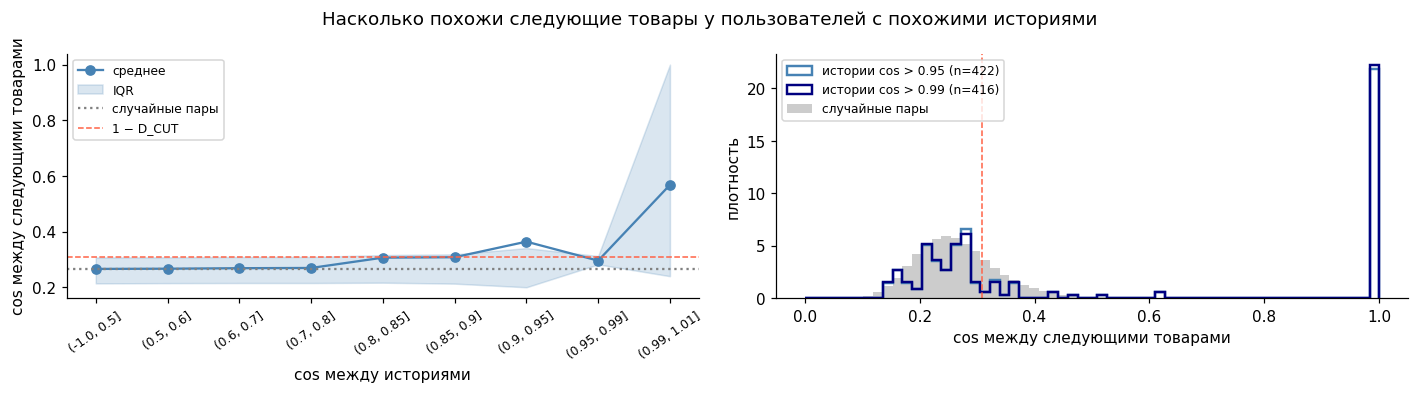

In [12]:
edges = np.array([-1, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.99, 1.01])
pairs['bin'] = pd.cut(pairs['hist_sim'], edges)
curve = pairs.groupby('bin', observed=True).agg(
    n=('next_sim', 'size'), next_sim=('next_sim', 'mean'),
    q25=('next_sim', lambda s: s.quantile(0.25)), q75=('next_sim', lambda s: s.quantile(0.75)),
    same_next=('same_next', 'mean'))
display(curve.round(3))

sim_close = 1 - D_CUT     # «в одном кластере» = ближе порога разреза
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
ax = axes[0]
xc = np.arange(len(curve))
ax.plot(xc, curve['next_sim'], 'o-', color='steelblue', label='среднее')
ax.fill_between(xc, curve['q25'], curve['q75'], color='steelblue', alpha=0.2, label='IQR')
ax.axhline(rand_next_sim, color='grey', ls=':', label='случайные пары')
ax.axhline(sim_close, color='tomato', ls='--', lw=1, label='1 − D_CUT')
ax.set_xticks(xc, [str(b) for b in curve.index], rotation=35, fontsize=8)
ax.set_xlabel('cos между историями'); ax.set_ylabel('cos между следующими товарами'); ax.legend(fontsize=8)

ax = axes[1]
bins = np.linspace(pairs['next_sim'].min(), 1, 60)
for lo, color in [(0.95, 'steelblue'), (0.99, 'navy')]:
    sel = pairs.loc[pairs['hist_sim'] > lo, 'next_sim']
    ax.hist(sel, bins, density=True, histtype='step', lw=1.6, color=color, label=f'истории cos > {lo} (n={len(sel)})')
ax.hist(pairs['next_sim'].iloc[len(a_nn):], bins, density=True, color='grey', alpha=0.4, label='случайные пары')
ax.axvline(sim_close, color='tomato', ls='--', lw=1)
ax.set_xlabel('cos между следующими товарами'); ax.set_ylabel('плотность'); ax.legend(fontsize=8)
fig.suptitle('Насколько похожи следующие товары у пользователей с похожими историями'); fig.tight_layout(); plt.show()

Как читать правый график. Унимодальное узкое P(i | h) при почти одинаковых историях дало бы
распределение cos между следующими товарами, прижатое к 1. Широкое, но одно облако дало бы
один сдвинутый горб. Многомодальность выглядит как смесь: часть пар попадает в одну моду
(правее красной линии), а часть лежит на уровне случайных пар, то есть в разных далёких модах.

### 2.2 Группы похожих историй

Группа = якорь + `GROUP − 1` ближайших по истории соседей. Её следующие товары кластеризуем
той же процедурой с равными весами (значимый кластер: не меньше `M_MIN` товаров группы).
Нули: `GROUP` случайных следующих товаров (случайный) и `GROUP` товаров каталога, ближайших
к центру следующих товаров группы (унимодальный). Результаты разбиты по плотности группы,
то есть по средней близости соседей к якорю.

In [13]:
anchors = rng.choice(N, size=min(N_ANCHORS, N), replace=False)
members = np.hstack([anchors[:, None], nn_idx[anchors, :GROUP - 1]])
tightness = nn_sim[anchors, :GROUP - 1].mean(1)

g_items = nxt[members]
centre = E[g_items].mean(1); centre /= np.linalg.norm(centre, axis=1, keepdims=True)
sets2 = {'данные': g_items,
         'унимодальный нуль': np.argsort(-(centre @ E.T), axis=1)[:, :GROUP],
         'случайный нуль': nxt[rng.integers(0, N, (len(anchors), GROUP))]}
Z2 = {name: [cos_linkage(E[s]) for s in S] for name, S in sets2.items()}
W2 = {name: [np.ones(GROUP)] * len(anchors) for name in sets2}

tab2 = sig_table(Z2, W2, D_CUT, M_MIN)
print(f'Число значимых кластеров среди {GROUP} следующих товаров группы; '
      f'D_CUT = {D_CUT:.3f}, M_MIN = {M_MIN} (≥{int(np.ceil(M_MIN * GROUP))} товаров)')
display(tab2.round(3))

# По квартилям плотности группы
quart = pd.qcut(tightness, 4, labels=[f'Q{k}' for k in range(1, 5)])
n_sig2 = np.array([n_significant(Z, w, D_CUT, M_MIN) for Z, w in zip(Z2['данные'], W2['данные'])])
spread = np.array([np.mean(pdist(E[s], 'cosine')) for s in g_items])
spread_rand = np.array([np.mean(pdist(E[s], 'cosine')) for s in sets2['случайный нуль']])
by_q = pd.DataFrame({'плотность': tightness, '≥2 значимых': n_sig2 >= 2, '0 (размыто)': n_sig2 == 0,
                     'разброс след. товаров': spread, 'q': quart}).groupby('q', observed=True).agg(
    плотность_от=('плотность', 'min'), плотность_до=('плотность', 'max'),
    доля_2plus=('≥2 значимых', 'mean'), доля_размыто=('0 (размыто)', 'mean'),
    разброс=('разброс след. товаров', 'mean'))
by_q['разброс / случайный'] = by_q['разброс'] / spread_rand.mean()
by_q.round(3)

Число значимых кластеров среди 20 следующих товаров группы; D_CUT = 0.691, M_MIN = 0.1 (≥2 товаров)


,0 (размыто),1,2,3+,≥2
данные,0.0,0.001,0.014,0.985,0.999
унимодальный нуль,0.0,0.995,0.005,0.000,0.005
случайный нуль,0.0,0.000,0.012,0.988,1.000


,плотность_от,плотность_до,доля_2plus,доля_размыто,разброс,разброс / случайный
q,,,,,,
Q1,0.608,0.696,0.999,0.0,0.731,0.997
Q2,0.696,0.713,1.000,0.0,0.731,0.997
Q3,0.713,0.730,1.000,0.0,0.730,0.996
Q4,0.730,0.928,0.997,0.0,0.728,0.993


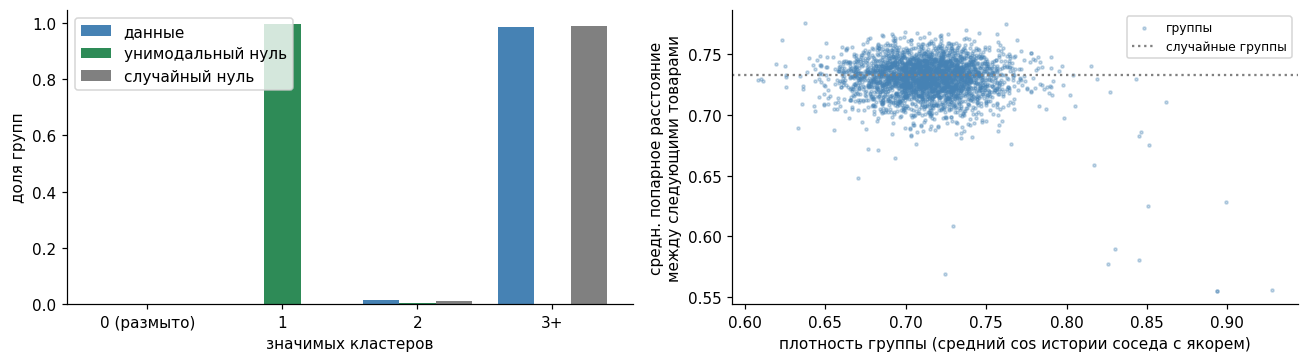

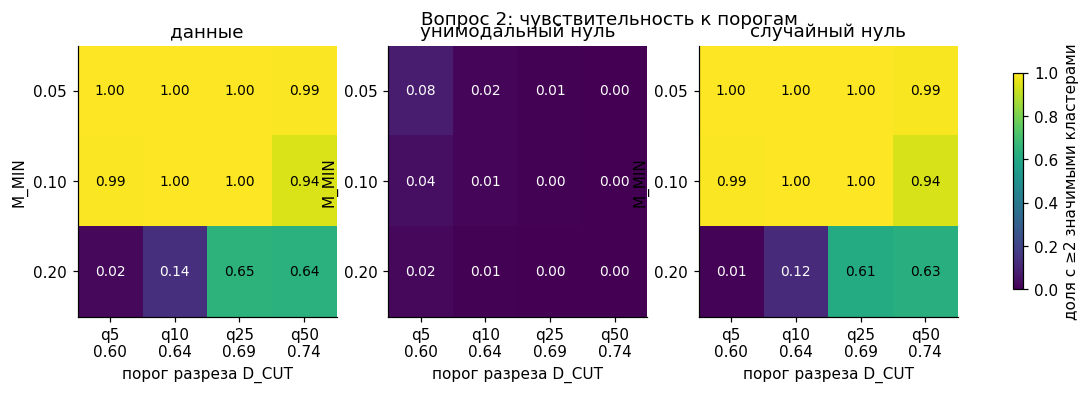

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
ax = axes[0]
colors2 = {'данные': 'steelblue', 'унимодальный нуль': 'seagreen', 'случайный нуль': 'grey'}
for k, (name, row) in enumerate(tab2.iterrows()):
    ax.bar(x + (k - 1) * width, row[['0 (размыто)', '1', '2', '3+']], width, color=colors2[name], label=name)
ax.set_xticks(x, ['0 (размыто)', '1', '2', '3+']); ax.set_xlabel('значимых кластеров')
ax.set_ylabel('доля групп'); ax.legend()

ax = axes[1]
ax.scatter(tightness, spread, s=4, alpha=0.3, color='steelblue', label='группы')
ax.axhline(spread_rand.mean(), color='grey', ls=':', label='случайные группы')
ax.set_xlabel('плотность группы (средний cos истории соседа с якорем)')
ax.set_ylabel('средн. попарное расстояние\nмежду следующими товарами'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

plot_sensitivity(sensitivity(Z2, W2), 'Вопрос 2: чувствительность к порогам')

Примеры: самые плотные группы (истории почти совпадают). Точки — следующие товары группы
(размер ∝ числу пользователей с этим товаром), × — последние товары истории якоря.

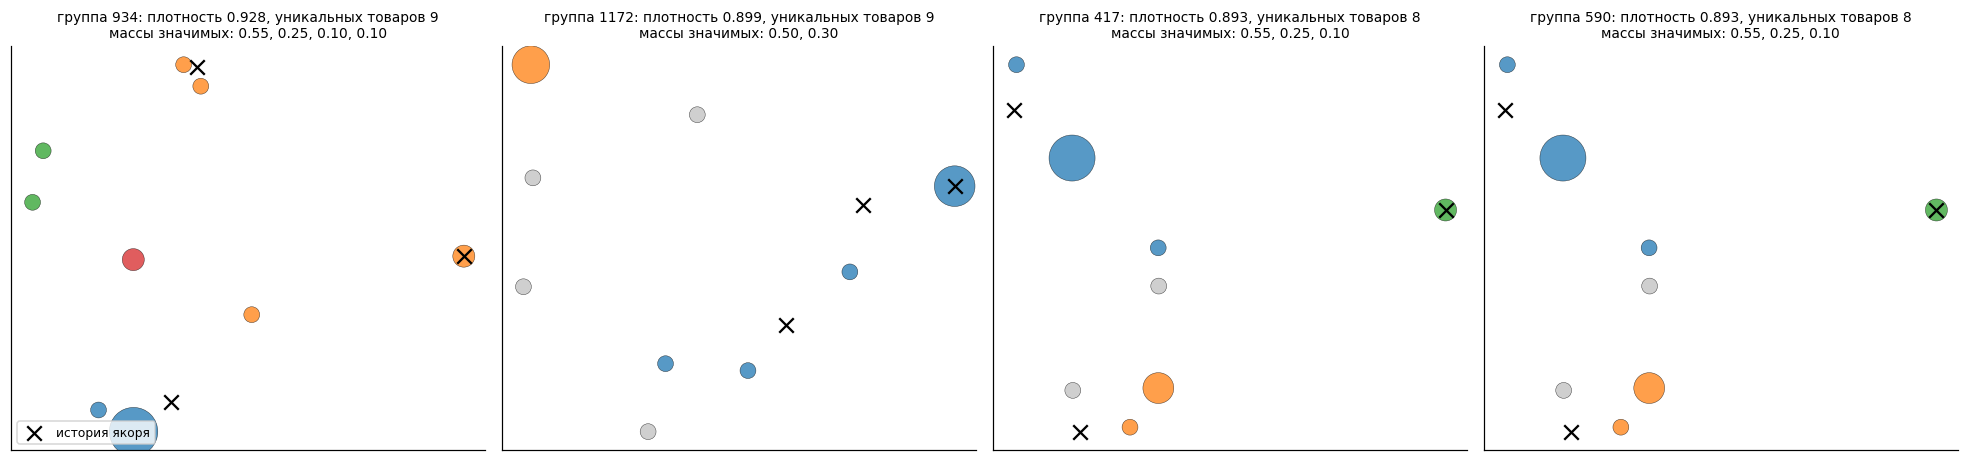

In [15]:
show = np.argsort(-tightness)[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, g in zip(axes, show):
    items, cnt = np.unique(g_items[g], return_counts=True)
    Zg = cos_linkage(E[items])      # уникальные товары, веса = кратности
    h = seqs[anchors[g]]; h = h[h != PAD]
    plot_modes(ax, items, cnt.astype(float), Zg, extra=[(h, 'x', 'история якоря')],
               title=f'группа {g}: плотность {tightness[g]:.3f}, уникальных товаров {len(items)}')
axes[0].legend(loc='lower left', fontsize=8)
fig.tight_layout(); plt.show()

## 3. Сводка

Доля пользователей (вопрос 1) и групп (вопрос 2) с ≥2 значимыми разнесёнными кластерами при
основных порогах. Разница «модель/данные − унимодальный нуль» оценивает многомодальность
сверх ложных срабатываний процедуры.

In [16]:
# Вопрос 1 при температуре обучения — проверка устойчивости к калибровке
p07, i07, cov07, _ = top_support(cos_test, TAU_TRAIN)
_, Z07, W07 = build_sets(p07, i07)
tab07 = sig_table({'SASRec': Z07['SASRec']}, {'SASRec': W07['SASRec']}, D_CUT, M_MIN)

summary = pd.DataFrame({
    'источник': [f'SASRec top-50, τ*={TAU:.3f}', f'SASRec top-50, τ={TAU_TRAIN}', f'группы из {GROUP} похожих историй'],
    '≥2 значимых': [tab1.loc['SASRec', '≥2'], tab07.loc['SASRec', '≥2'], tab2.loc['данные', '≥2']],
    '0 (размыто)': [tab1.loc['SASRec', '0 (размыто)'], tab07.loc['SASRec', '0 (размыто)'], tab2.loc['данные', '0 (размыто)']],
    '≥2, унимодальный нуль': [tab1.loc['унимодальный нуль', '≥2'], np.nan, tab2.loc['унимодальный нуль', '≥2']],
    '≥2, случайный нуль': [tab1.loc['случайный нуль', '≥2'], np.nan, tab2.loc['случайный нуль', '≥2']],
}).set_index('источник')
print(f'D_CUT = {D_CUT:.3f} (q{int(CUT_Q * 100)} случайных пар), M_MIN = {M_MIN}; '
      f'масса top-50: τ* {coverage.mean():.2f}, τ=0.07 {cov07.mean():.2f}')
summary.round(3)

D_CUT = 0.691 (q25 случайных пар), M_MIN = 0.1; масса top-50: τ* 0.04, τ=0.07 0.30


,≥2 значимых,0 (размыто),"≥2, унимодальный нуль","≥2, случайный нуль"
источник,,,,
"SASRec top-50, τ*=0.152",0.988,0.0,0.001,0.981
"SASRec top-50, τ=0.07",0.951,0.0,NaN,NaN
группы из 20 похожих историй,0.999,0.0,0.005,1.000


### Выводы

Цифры ниже относятся к прогону с `CUT_Q = 0.25`, `M_MIN = 0.1`, `SEED = 42`.

**0. Текстовое пространство почти не структурирует переходы.** Расстояние от последнего
товара истории до следующего распределено почти так же, как у случайных пар (медианы 0.738
и 0.740). Соседние товары в последовательности в текстовом пространстве почти не связаны.

**1. SASRec.** После калибровки по val τ* ≈ 0.15, и P(i | h) очень плоское: top-50 держит
≈ 4 % массы, exp(H) ≈ 8.8 тыс. товаров из 11.9 тыс. У 98.8 % пользователей в top-50 есть
≥ 2 значимых разнесённых кластера, но у случайного нуля таких 98.1 %, и на всей сетке
порогов SASRec от случайного нуля почти не отличается. Унимодальный нуль даёт ≈ 0 %, то есть
процедура не срабатывает на пустом месте: она видит кластеры там, где они есть. Top-50
SASRec разбросан по текстовому пространству как случайные товары. Кластеры есть, но это
кластеры самого каталога, а не моды, специфичные для истории. Таргет попадает во
второстепенные значимые кластеры с частотой, которую предсказывает их масса (0.36 против
0.37), но таких пользователей всего 179, а распределение близко к равномерному.

**2. Данные.** Соседи по истории заметно ближе случайных пар (cos 0.69–0.76 против медианы
0.52), а разброс их следующих товаров равен разбросу случайных групп (отношение 0.99–1.00
во всех квартилях плотности). Близость следующих товаров остаётся на случайном уровне
вплоть до cos историй ≈ 0.99. Среди почти совпадающих историй (416 пар) распределение
бимодально: 42 % пар имеют *тот же самый* товар, остальные лежат на уровне случайных пар,
и промежуточной «соседней» моды нет.

**Итог.** Гипотеза «P(i | h) распадается на несколько разнесённых мод, специфичных для
истории» в этом текстовом пространстве не подтверждается. Верно более сильное утверждение:
условное распределение следующего товара в текстовом пространстве почти совпадает с
маргинальным по каталогу. Формально оно многомодально, но эту многомодальность оно
наследует от кластерной структуры каталога, а не от истории. Для генеративной постановки
это значит, что точечная регрессия в среднее действительно попадает в «пустоту» между
кластерами каталога. Но история почти не сдвигает распределение в текстовой геометрии,
поэтому сигнал о следующем товаре лежит в основном вне текстового сходства.

**Ограничения.** SASRec здесь ID-модель со слабым качеством (HR@20 ≈ 0.06), и её
предпочтения не обязаны согласовываться с текстом. Проверку стоит повторить с текстовой
моделью (`CONFIG_PATH = 'configs/sasrec_alphafuse.yaml'`, `CKPT_DIR = 'checkpoints/sasrec_alphafuse'`)
и в отбелённом пространстве. Датасет маленький (19 тыс. историй), поэтому по-настоящему
похожих историй мало, и вывод вопроса 2 для самых плотных групп держится на сотнях пар.